In [10]:
import numpy as np
import pandas as pd
import os
import glob

In [24]:
# load 
df_all = pd.read_parquet('./STUV_0128_0514.parquet')

# Fig S2C (suppl.) for all recorded day

In [178]:
with mpl.rc_context(rc_dict_boxplot):
    
    month_day_combos = df_all[['day', 'month']].drop_duplicates()
    for ii in range(len(month_day_combos)):
        fig,axes = plt.subplots(5,1,figsize=(4,3),sharey='col',sharex=True)
        day,month = month_day_combos.iloc[ii]
        for tt,motor_tilt in enumerate([18,13,3,-7,-18]):
            
            df_= df_all[(df_all['day'] == day) & (df_all['month'] == month)& (df_all['motor_tilt'] == motor_tilt)]
            df_sorted = df_.sort_values(by='unix_ts', ascending=False)
            # seconds since midnight
            df_sorted['time_of_day_sec'] = (
                df_sorted['hour'] * 3600 +
                df_sorted['minute'] * 60 +
                df_sorted['second']
            )
            df_sorted['norm_int_auc_s'] = df_sorted['auc_scone']/df_sorted['int_t']
            df_sorted['norm_int_auc_m'] = df_sorted['auc_mcone']/df_sorted['int_t']
            axes[tt].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_m'],color='green')
            axes[tt].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_s'],color='blue')
            axes[tt].spines['top'].set_visible(False);axes[tt].spines['bottom'].set_visible(False)
            axes[tt].set_yscale('log')
            
            axes_ms = axes[tt].twinx()
            axes_ms.spines['top'].set_visible(False);axes_ms.spines['bottom'].set_visible(False)
            axes_ms.plot(df_sorted['time_of_day_sec'],df_sorted['auc_m_over_s'],color='k')

            if tt<4:
                axes[tt].xaxis.set_visible(False)
                axes_ms.xaxis.set_visible(False)
            else:
                axes[tt].set_xticks([ii*3600 for ii in [7,11,15,19]]);axes[tt].set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
                axes_ms.set_xticks([ii*3600 for ii in [7,11,15,19]]);axes_ms.set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
        fig.savefig(f'./Fig2B_month{month}_day{day}.png')
        plt.close()

# Fig 2C paper two chosen single-day examples

In [226]:
with mpl.rc_context(rc_dict_boxplot):
    chosen_day_months = [[14,5],[19,4]]
    for ii in range(len(chosen_day_months)):
        fig,axes = plt.subplots(6,1,figsize=(4,4),sharex=True)
        day,month = chosen_day_months[ii]
        print(day,month)
        for tt,motor_tilt in enumerate([18,13,3,-7,-18]):
            
            df_= df_all[(df_all['day'] == day) & (df_all['month'] == month)& (df_all['motor_tilt'] == motor_tilt)]
            df_sorted = df_.sort_values(by='unix_ts', ascending=False)
            # seconds since midnight
            df_sorted['time_of_day_sec'] = (
                df_sorted['hour'] * 3600 +
                df_sorted['minute'] * 60 +
                df_sorted['second']
            )
            x_min,x_max=min(df_sorted['time_of_day_sec']),max(df_sorted['time_of_day_sec'])
            axes[tt].set_xlim([x_min,x_max])
            df_sorted['norm_int_auc_s'] = df_sorted['auc_scone']/df_sorted['int_t']
            df_sorted['norm_int_auc_m'] = df_sorted['auc_mcone']/df_sorted['int_t']
            axes[tt].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_m'],color='green')
            axes[tt].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_s'],color='blue')
            axes[tt].spines['top'].set_visible(False);axes[tt].spines['bottom'].set_visible(False)
            axes[tt].set_yscale('log')
            
            axes_ms = axes[tt].twinx()
            axes_ms.spines['top'].set_visible(False)
            axes_ms.plot(df_sorted['time_of_day_sec'],df_sorted['auc_m_over_s'],color='k')

            if tt<4:
                axes[tt].xaxis.set_visible(False)
                axes_ms.xaxis.set_visible(False)
            else:
                axes[tt].set_xticks([ii*3600 for ii in [7,11,15,19]]);axes[tt].set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
                axes_ms.set_xticks([ii*3600 for ii in [7,11,15,19]]);axes_ms.set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
            axes[tt].sharey(axes[0])
        ## weather info
        print(month,day)
        df_w = pd.read_csv(f"./weather_month{month}_day{day}.csv",skiprows=2)
        df_w.columns = [ "time",
        "temperature_C",
        "relative_humidity",
        "precipitation",
        "cloud_cover",
        "wind_speed_kmh"]
        # convert time column
        df_w["time"] = pd.to_datetime(df["time"])
        df_w['time_of_day_sec'] = df_w['time'].dt.hour * 3600 +df_w['time'].dt.minute * 60 +df_w['time'].dt.second
        #axes[-1].plot(df_w["time_of_day_sec"], df_w["temperature_C"],color='orange',linestyle='dashed')
        axes[-1].plot(df_w["time_of_day_sec"], df_w["precipitation"],color='gray',linestyle='dashed',label='rain (mm)')
        axes_cloud = axes[-1].twinx()
        axes_cloud.plot(df_w["time_of_day_sec"], df_w["cloud_cover"],color='gray',linestyle='solid',label='cloud_cover(%)')
        axes[-1].set_xticks([ii*3600 for ii in [7,11,15,19]]);axes[-1].set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
        axes_cloud.set_xticks([ii*3600 for ii in [7,11,15,19]]);axes_cloud.set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
        axes[-1].spines['top'].set_visible(False);axes[-1].set_ylabel('Rain (mm)')
        axes_cloud.spines['top'].set_visible(False);axes_cloud.set_ylabel('Cloud cover(%)')
        axes[-1].set_yscale('linear')
        fig.savefig(f'./Fig2B_month{month}_day{day}_w_weather.svg')
        plt.close()

14 5
5 14
19 4
4 19


# Fig2D test area

## spectra plotting

28 3
14 5


[Text(25200, 0, '7 a.m.'),
 Text(32400, 0, '9 a.m.'),
 Text(39600, 0, '11 a.m.'),
 Text(46800, 0, '1 p.m.'),
 Text(54000, 0, '3 p.m.'),
 Text(61200, 0, '5 p.m.'),
 Text(68400, 0, '7 p.m.'),
 Text(75600, 0, '9 p.m.')]

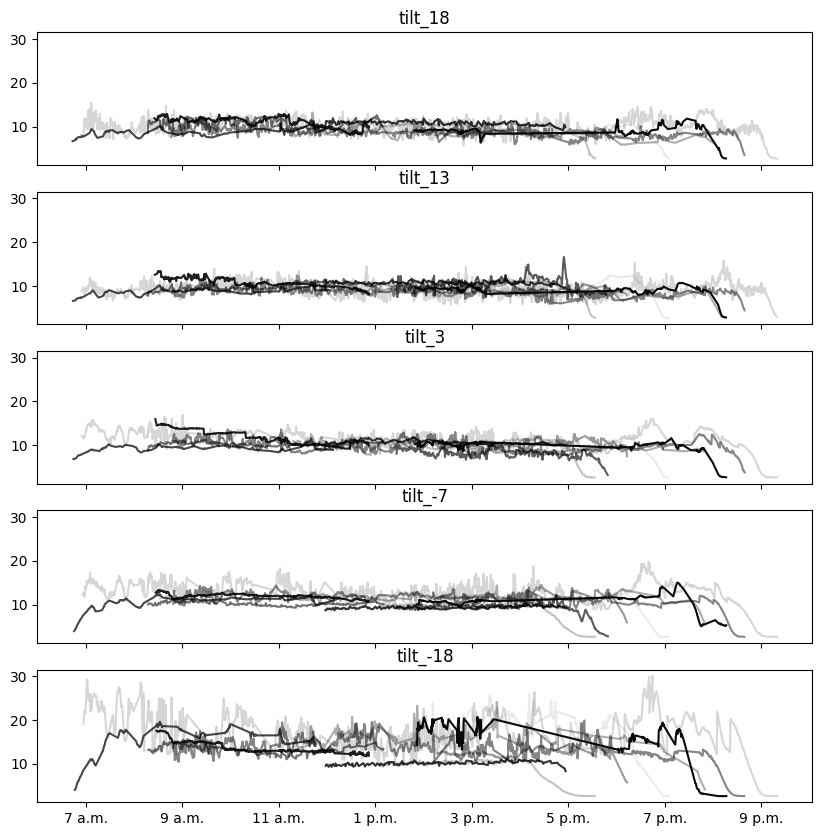

In [98]:
fig,axes = plt.subplots(5,1,figsize=(10,10),sharex=True,sharey=True)
for tt,motor_tilt in enumerate([18,13,3,-7,-18]):
    month_day_combos = df_all[['day', 'month']].drop_duplicates()
    for ii in range(len(month_day_combos)):
        day,month = month_day_combos.iloc[ii]
        df_= df_all[(df_all['day'] == day) & (df_all['month'] == month)& (df_all['motor_tilt'] == motor_tilt)]
        df_sorted = df_.sort_values(by='unix_ts', ascending=False)
        # seconds since midnight
        df_sorted['time_of_day_sec'] = (
            df_sorted['hour'] * 3600 +
            df_sorted['minute'] * 60 +
            df_sorted['second']
        )
        if np.max(df_sorted['auc_m_over_s'])>25:
            print(day,month)
        axes[tt].plot(df_sorted['time_of_day_sec'],df_sorted['auc_m_over_s'],color='k',alpha=0.08+0.08*ii)
        axes[tt].set_title(f'tilt_{motor_tilt}')
axes[-1].set_xticks([ii*3600 for ii in [7,9,11,13,15,17,19,21]])
axes[-1].set_xticklabels(['7 a.m.','9 a.m.','11 a.m.','1 p.m.','3 p.m.','5 p.m.','7 p.m.','9 p.m.'])
#axes[-1].set_xticks([ii*3600 for ii in [7,11,15,19]])
#axes[-1].set_xticklabels([7,11,15,19])

## weather.csv plotting

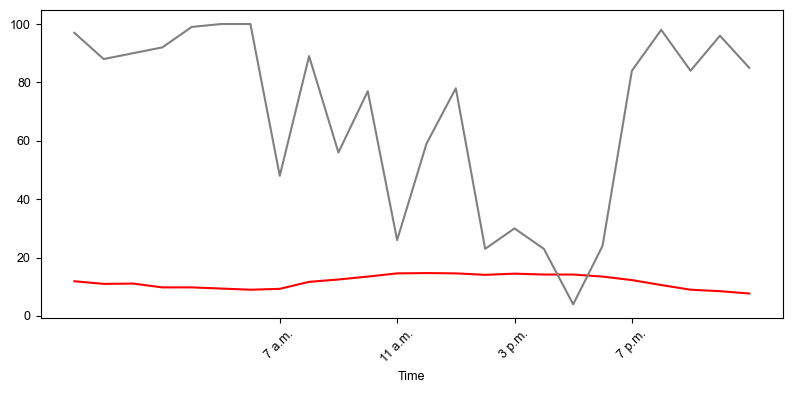

In [222]:
df = pd.read_csv(
    f"weather_month{month}_day{day}.csv",
    skiprows=2
)

# rename columns for convenience
df.columns = [
    "time",
    "temperature_C",
    "relative_humidity",
    "precipitation",
    "cloud_cover",
    "wind_speed_kmh"
]

# convert time column
df["time"] = pd.to_datetime(df["time"])
df['time_of_day_sec'] = df['time'].dt.hour * 3600 +df['time'].dt.minute * 60 +df['time'].dt.second

# plot
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df["time_of_day_sec"], df["temperature_C"],color='red')
#ax.plot(df["time_of_day_sec"], df["precipitation"],color='blue')
ax.plot(df["time_of_day_sec"], df["cloud_cover"],color='gray')
ax.set_xticks([ii*3600 for ii in [7,11,15,19]]);ax.set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
ax.set_xlabel("Time")
# ax.set_ylabel("Temperature (°C)")
# ax.set_title("Temperature over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [194]:
df.columns

Index(['time', 'temperature_C', 'relative_humidity', 'dewpoint_C',
       'precipitation_mm', 'wind_speed_kmh', 'time_of_day_sec'],
      dtype='object')

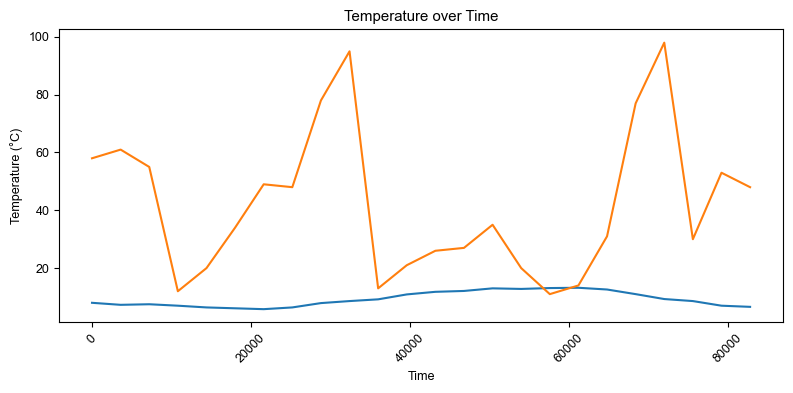

In [195]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df["time_of_day_sec"], df["temperature_C"])
ax.plot(df["time_of_day_sec"], df["precipitation_mm"])

ax.set_xlabel("Time")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature over Time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Fig2D

In [136]:
import matplotlib as mpl
from matplotlib import rcParams
## font manage
import matplotlib.font_manager as fm
font_path = '/gpfs01/euler/User/ydeng/Resource/Fonts/Arial.ttf'
font_prop = fm.FontProperties(fname=font_path)
fm.fontManager.addfont(font_path)
arial_font_name = font_prop.get_name()
print(f"Added font: {arial_font_name}")
rcParams['font.family'] = arial_font_name
rcParams['font.size'] = 9  # Common font size for all text
rcParams['svg.fonttype'] = 'none' # Ensure fonts are embedded as text, not converted to paths

Added font: Arial


In [164]:
rc_dict_boxplot = {'figure.dpi': 400,
                   'figure.figsize': [6, 4],
                   'figure.frameon': False,
                   'svg.fonttype':'none',
                   'font.family' :arial_font_name, 
    'font.size':9,
 'lines.markersize': 0.5,
 'lines.linewidth': .5,
 'lines.markeredgewidth': 0.5,
 'legend.columnspacing': 0.5,
 'legend.frameon': False,
 'legend.markerscale': 0.4,
 'legend.labelspacing': 0.1,
 'legend.handletextpad': 0,
 'legend.loc': 'lower right',
    'legend.fontsize': 9,
 'axes.labelpad': 1.0,
 'xtick.major.pad': 1,
 'ytick.major.pad': 1}

In [151]:
bin_edges = np.linspace(0,30, 30) # xx equally spaced bins

/tmp/ipykernel_151727/3436046521.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


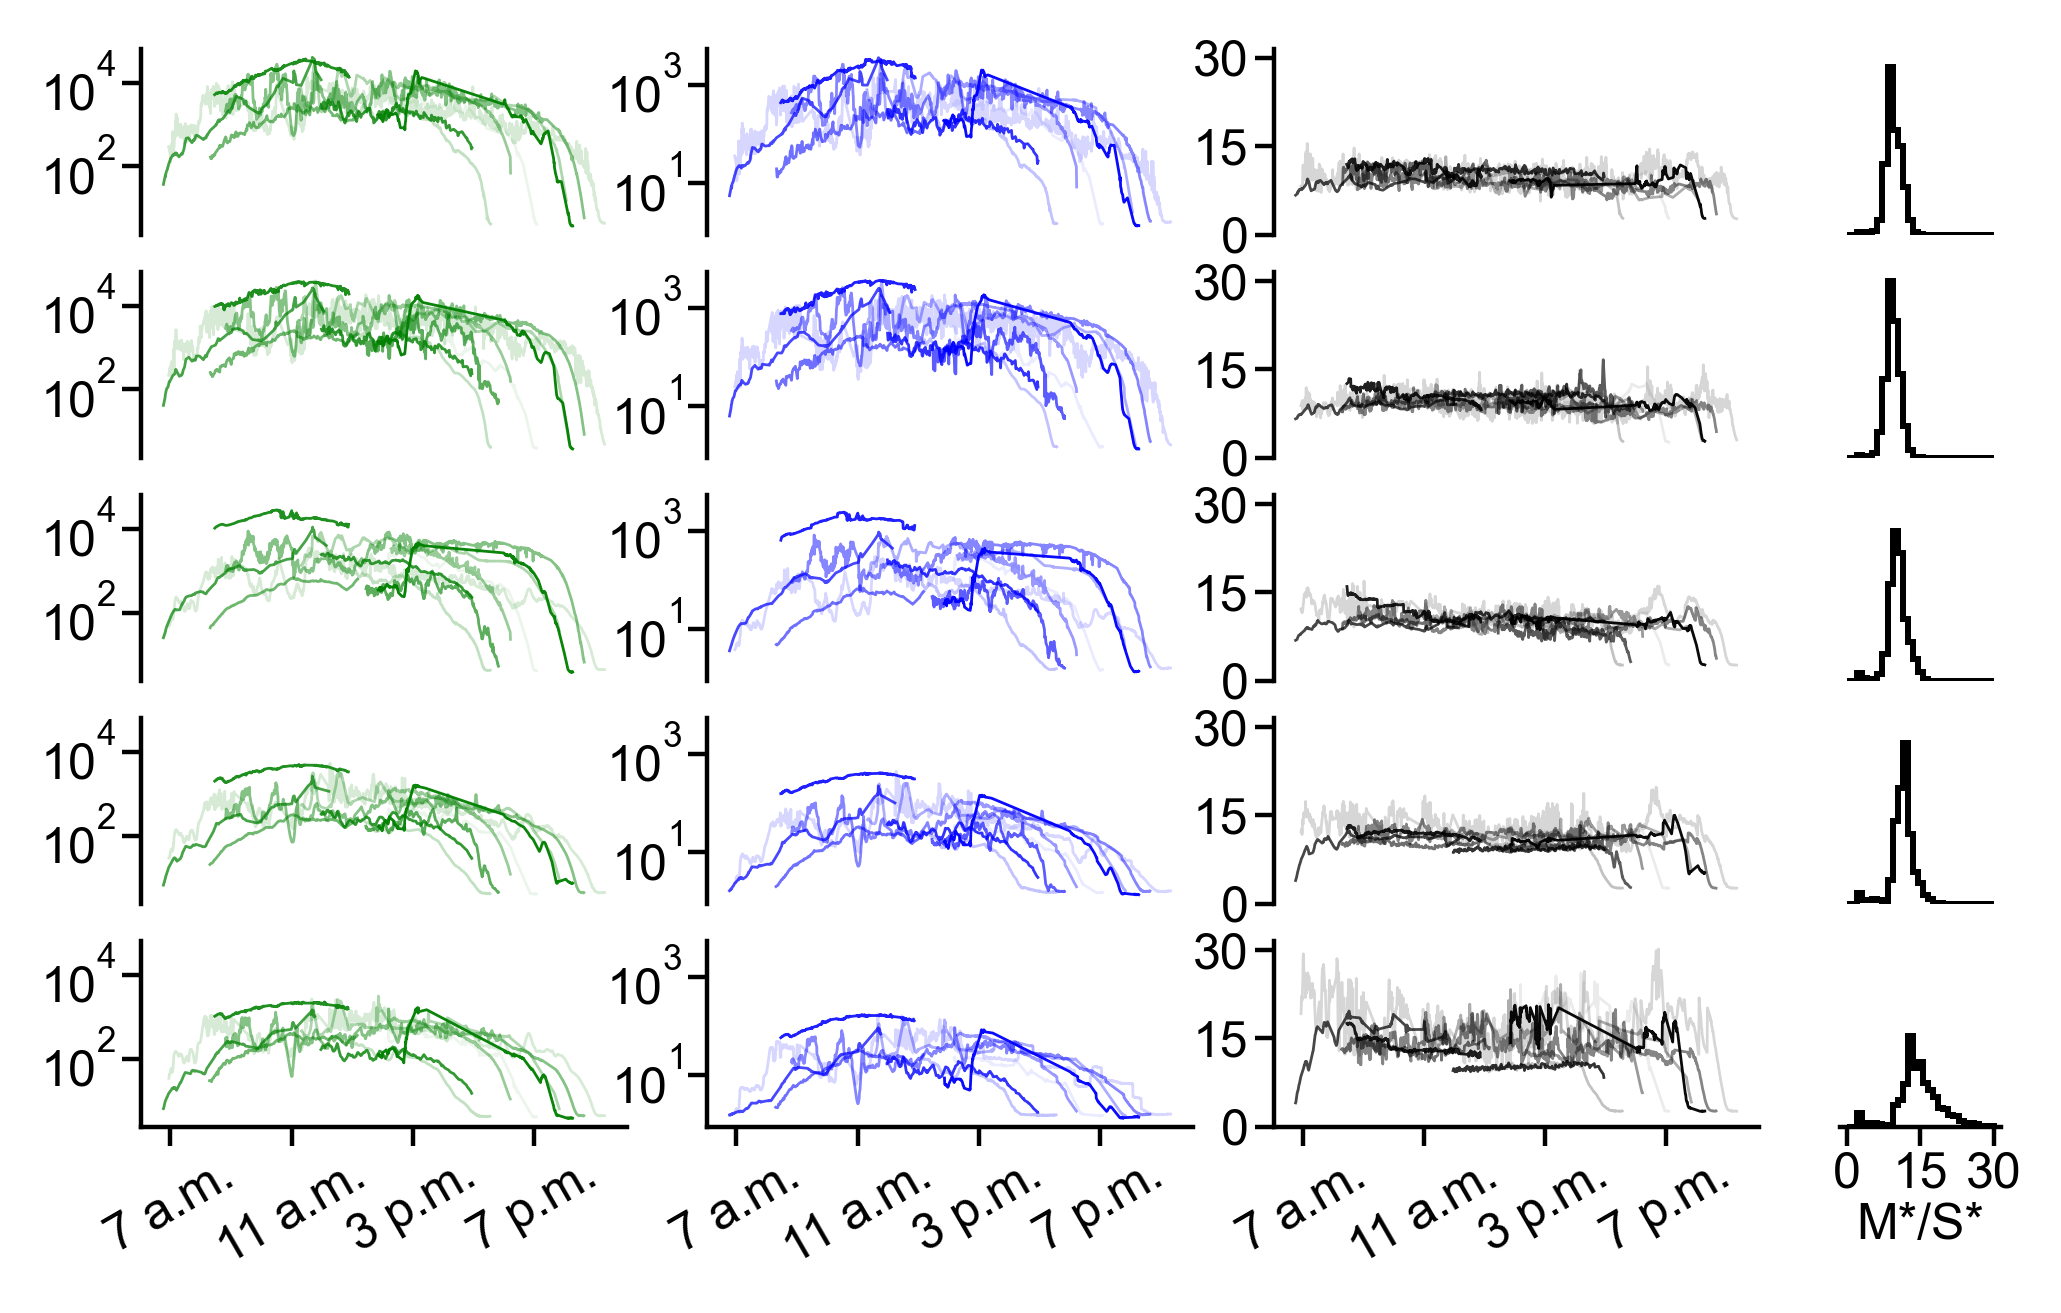

In [165]:
with mpl.rc_context(rc_dict_boxplot):
    fig,axes = plt.subplots(
    5,
    4,
    figsize=(6,3.5),
    sharey='col',
    gridspec_kw={'width_ratios': [1.5,1.5,1.5,0.5],
                'wspace': 0.2}) # 0-> almost touching
    for tt,motor_tilt in enumerate([18,13,3,-7,-18]):
        df_m_over_s = df_all[df_all['motor_tilt'] == motor_tilt]
        m_over_s_per_tilt = df_m_over_s['auc_m_over_s']
        month_day_combos = df_all[['day', 'month']].drop_duplicates()
        for ii in range(len(month_day_combos)):
            day,month = month_day_combos.iloc[ii]
            df_= df_all[(df_all['day'] == day) & (df_all['month'] == month)& (df_all['motor_tilt'] == motor_tilt)]
            df_sorted = df_.sort_values(by='unix_ts', ascending=False)
            # seconds since midnight
            df_sorted['time_of_day_sec'] = (
                df_sorted['hour'] * 3600 +
                df_sorted['minute'] * 60 +
                df_sorted['second']
            )
            df_sorted['norm_int_auc_s'] = df_sorted['auc_scone']/df_sorted['int_t']
            df_sorted['norm_int_auc_m'] = df_sorted['auc_mcone']/df_sorted['int_t']
            axes[tt,0].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_m'],color='green',alpha=0.08+0.08*ii)
            axes[tt,1].plot(df_sorted['time_of_day_sec'],df_sorted['norm_int_auc_s'],color='blue',alpha=0.08+0.08*ii)
            axes[tt,2].plot(df_sorted['time_of_day_sec'],df_sorted['auc_m_over_s'],color='k',alpha=0.08+0.08*ii)
            axes[tt,3].hist(m_over_s_per_tilt,bins=bin_edges,color='k',histtype='step')
            for col in range(4):
                axes[tt,col].spines['top'].set_visible(False);axes[tt,col].spines['right'].set_visible(False)
                if tt<4:
                    axes[tt,col].spines['bottom'].set_visible(False)
                    axes[tt,col].tick_params(bottom=False, labelbottom=False)
            axes[tt,0].set_yscale('log')
            axes[tt,1].set_yscale('log')
        axes[tt,2].set_yticks([0,15,30])
        axes[tt,2].set_yticklabels([0,15,30])
        axes[tt,-1].set_yticks([]);axes[tt,-1].set_yticklabels([]);axes[tt,-1].spines['left'].set_visible(False)
    for col in range(3):
        
        #axes[-1,col].set_xticks([ii*3600 for ii in [7,9,11,13,15,17,19,21]])
        #axes[-1,col].set_xticklabels(['7 a.m.','9 a.m.','11 a.m.','1 p.m.','3 p.m.','5 p.m.','7 p.m.','9 p.m.'], rotation = 30)
        axes[-1,col].set_xticks([ii*3600 for ii in [7,11,15,19]])
        axes[-1,col].set_xticklabels(['7 a.m.','11 a.m.','3 p.m.','7 p.m.'], rotation = 30)
    axes[-1,-1].set_xlabel('M*/S*')
    axes[-1,-1].set_xticks([0,15,30])
    axes[-1,-1].set_xticklabels([0,15,30])
    
    #axes[-1].set_xticks([ii*3600 for ii in [7,11,15,19]])
    #axes[-1].set_xticklabels([7,11,15,19])
    plt.tight_layout()
    plt.savefig('./Fig2D_spectra_pop.svg')